# Running on qBraid

This notebook is ready to run on **qBraid** with the **QGSS 2026** environment — no `pip install` needed.

1. Make sure the **QGSS 2026** environment is installed.
2. Select the **Python 3 [QGSS 2026]** kernel (kernel picker, top-right), then run the cells.

# Lab 4: Towards quantum advantage

# Chapter 4: Sample-based Quantum Diagonalization

### Table of Contents

- Exercise 1: Map LUCJ circuit to the Nighthawk device
- Exercise 2: Examine the resulting bitstring
- Exercise 3: Recover the bitstring
- Exercise 4: Freeze subspace configurations
- Scored Exercise: Find your best subspace!


In this chapter you will estimate the **ground-state energy** of the nitrogen molecule (N₂) on a real quantum computer using **Sample-based Quantum Diagonalization (SQD)**.

SQD is a hybrid quantum–classical method: the quantum computer runs a parameterized circuit and *proposes* which electron arrangements are most important, while the classical computer does the linear algebra — diagonalizing the molecular Hamiltonian in that small, smartly chosen set of configurations.

By the end of this chapter you will have mapped a chemistry circuit to two different IBM device topologies, cleaned up noisy hardware bitstrings, and beaten the Hartree–Fock energy on real quantum hardware.

## Background: Molecular quantum chemistry in 5 minutes

You do **not** need a chemistry background to complete this lab. This section gives you just enough vocabulary.

### Molecules, orbitals, and electrons

Think of a molecule as a small concert hall.
The **molecular orbitals** are the seats in that hall.
The **electrons** are the guests who must be seated according to one strict rule: each seat (orbital) can hold *at most one guest of a given spin* — this is the Pauli exclusion principle.

Each spatial orbital can host two electrons, one with **spin-α (↑)** and one with **spin-β (↓)**.
We always track the two spin flavors separately, which is exactly why the bitstrings you will measure later are split into an α half and a β half.

### The ground state and why it matters

The **ground state** is the lowest-total-energy seating arrangement.
It tells chemists whether a molecule is stable, how strong its bonds are, and whether it will react.
Computing the ground-state energy accurately is one of the most compelling near-term applications of quantum computers because the number of possible seatings grows *exponentially* — for $n$ orbitals and $N_e$ electrons there are $\binom{n}{N_e}$ arrangements per spin species, which quickly exceeds any classical computer's reach.

Mathematically, the problem is:

$$E_0 = \min_{\psi} \frac{\langle \psi | \hat{H} | \psi \rangle}{\langle \psi | \psi \rangle}$$

We want the lowest eigenvalue of the molecular Hamiltonian $\hat{H}$.

### Classical reference methods

Two classical methods provide the benchmark lines in our plots:

| Method | What it does | Accuracy |
|---|---|---|
| **Hartree–Fock (HF)** | Each electron ignores every other and picks the cheapest seat independently. Fast, but ignores electron *correlation* — the tendency of electrons to dodge each other. | Upper bound on $E_0$; rough estimation. |
| **CCSD** (Coupled Cluster Singles & Doubles) | Starts from HF, then adds 1- and 2-electron "jumps" out of the HF arrangement using algebraic amplitudes $t_1$ (singles) and $t_2$ (doubles). Captures most correlation. | Near-exact for many molecules; our gold-standard comparison. |

> **Key point:** We will also *use* CCSD to seed our quantum circuit — its amplitudes describe how electrons want to jump between orbitals, and we transplant that chemical intuition directly into the parameters of the quantum ansatz.

In [ ]:
# ✅ QGSS 2026 kernel check — run this first.
# Verifies this notebook is running on the 'Python 3 [QGSS 2026]' kernel.
# If it isn't, the output explains exactly how to install/add/select it.
from qbraid_kernel_check import check_qgss_kernel

check_qgss_kernel()

In [ ]:
# Version display
!uv pip show qiskit qiskit-ibm-runtime qiskit-addon-sqd ffsim

In [33]:
# Import necessary packages
import warnings
warnings.filterwarnings("ignore")

import copy
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
from typing import cast
from itertools import combinations
from functools import partial

import pyscf
import pyscf.cc
import pyscf.mcscf
import ffsim

from qiskit.circuit import QuantumCircuit, QuantumRegister, CircuitInstruction, Barrier
from qiskit.transpiler import generate_preset_pass_manager
from qiskit.visualization import plot_error_map
from qiskit_ibm_runtime import QiskitRuntimeService, Sampler
from qiskit_ibm_runtime.fake_provider import FakeMiami

from qiskit_addon_sqd.fermion import SCIResult, solve_sci_batch
from qiskit_addon_sqd.subsampling import subsample
from qiskit_addon_sqd.counts import bit_array_to_arrays, bitstring_matrix_to_integers

In [ ]:
from qc_grader.challenges.qgss_2026 import (
    grade_lab4c_ex1a,
    grade_lab4c_ex1b,
    grade_lab4c_ex2a,
    grade_lab4c_ex2b,
    grade_lab4c_ex3a,
    grade_lab4c_ex3b,
    grade_lab4c_ex4,
    grade_lab4c_exbonus,
)


## 1. Building the N₂ molecule and its Hamiltonian

### The nitrogen molecule

We study **molecular nitrogen (N₂)**: two nitrogen atoms separated by 2.0 Å.
We describe the molecule using the **`cc-pvdz` basis set** — a standard vocabulary of orbital shapes that balances accuracy with computational cost.
Running Hartree–Fock in this basis gives us 28 spatial orbitals in total.

### Active space and frozen orbitals

Not all orbitals matter equally.
The innermost **core** orbitals (the 1s electrons of each nitrogen atom) sit deep in energy and essentially never change — they are perfectly happy where they are no matter what the molecule does.
Computing those orbitals quantum-mechanically would waste precious qubits.

We therefore **freeze** them:
- `n_frozen = 2` removes the 2 lowest-energy core orbitals from the quantum treatment.
- `active_space = range(n_frozen, mol.nao_nr())` is the set of orbitals where the chemically interesting action — bond formation, electron correlation — actually happens.

This is the **active-space approximation**: solve the full HF over everything, then only treat the active-space electrons on the quantum computer.
After freezing, we are left with:
- `num_orbitals` active spatial orbitals → this will equal the number of qubits per spin sector.
- `(num_elec_a, num_elec_b)` active electrons of spin-α and spin-β.  N₂ is a closed-shell singlet, so `num_elec_a == num_elec_b`.

The code cell below also extracts the **one-electron integrals** (`hcore`), **two-electron repulsion integrals** (`eri`), and the constant **nuclear repulsion energy** — together these are the numerical representation of $\hat{H}$ restricted to the active space, which the classical eigensolver will diagonalize later.

In [3]:
# Build N2 molecule
mol = pyscf.gto.Mole()
mol.build(
    atom=[["N", (0, 0, 0)], ["N", (2.0, 0, 0)]],
    basis="cc-pvdz",
)

# Define active space
n_frozen = 2
active_space = range(n_frozen, mol.nao_nr())

# Get molecular integrals
scf = pyscf.scf.RHF(mol).run()
num_orbitals = len(active_space)
n_electrons = int(sum(scf.mo_occ[active_space]))
num_elec_a = (n_electrons + mol.spin) // 2
num_elec_b = (n_electrons - mol.spin) // 2
cas = pyscf.mcscf.CASCI(scf, num_orbitals, (num_elec_a, num_elec_b))
mo = cas.sort_mo(active_space, base=0)
hcore, nuclear_repulsion_energy = cas.get_h1cas(mo)
eri = pyscf.ao2mo.restore(1, cas.get_h2cas(mo), num_orbitals)

# Print molecular information
print(f"Number of molecular orbitals: {num_orbitals}")
print(f"Number of electrons (a, b): {(num_elec_a, num_elec_b)}")

converged SCF energy = -108.33058275366
Number of molecular orbitals: 26
Number of electrons (a, b): (5, 5)


### Running CCSD to seed the quantum ansatz

Before we build the quantum circuit, we run **CCSD** classically.
We are *not* using CCSD as the final answer — that would defeat the purpose.
We are **mining it for its amplitudes**:

- `t1[i, a]` — the amplitude for a single electron to "jump" from occupied orbital $i$ to virtual orbital $a$.
- `t2[i, j, a, b]` — the amplitude for an electron *pair* to scatter from $(i, j)$ to $(a, b)$.

These amplitudes encode CCSD's chemical intuition about how electrons correlate.
In the next section, the `ffsim` library will read them and compile them into the rotation angles of the quantum circuit, effectively transplanting classical chemistry knowledge into the quantum device as a high-quality starting guess.

In [4]:
# Get CCSD t2 amplitudes for initializing the ansatz
ccsd = pyscf.cc.CCSD(scf, frozen=[i for i in range(mol.nao_nr()) if i not in active_space]).run(max_cycle=1000)
t1 = ccsd.t1
t2 = ccsd.t2

E(CCSD) = -108.9095206696613  E_corr = -0.5789379160014551


## 2. Quantum state preparation: the LUCJ ansatz

### What is the LUCJ ansatz?

The goal of state preparation is to build a quantum circuit that approximates the N₂ ground state well enough that sampling it yields electron configurations close to the true ground state.
We use the **(L)UCJ ansatz** — **(Local) Unitary Cluster Jastrow** — a hardware-efficient parameterized circuit that captures electron correlation through two ingredients:

1. **Orbital rotations** $e^{i\hat{K}}$: one-body unitaries that mix the molecular orbitals (think of them as rearranging the seats).
2. **Jastrow factor** $e^{i\sum_{pq} J_{pq}\,\hat{n}_p \hat{n}_q}$: a diagonal interaction that penalizes or rewards pairs of electrons simultaneously occupying orbitals $p$ and $q$ (electrons react to each other's presence).

One UCJ layer has the form:

$$U_\mu = e^{i\hat{K}_\mu}\; e^{i\sum_{p<q} J^{(\mu)}_{pq}\,\hat{n}_p \hat{n}_q}\; e^{-i\hat{K}_\mu}$$

where $\hat{n}_p = a^\dagger_p a_p$ is the occupation-number operator for orbital $p$.
The full ansatz stacks `n_reps` such layers: $U = U_{n_\text{reps}} \cdots U_1$.
Here we use `n_reps = 1`.

### From CCSD amplitudes to circuit parameters

`ffsim.UCJOpSpinBalanced.from_t_amplitudes(t1, t2, n_reps, interaction_pairs)` reads the CCSD single- and double-excitation amplitudes and compiles them into the rotation angles $K_\mu$ and Jastrow couplings $J_{pq}^{(\mu)}$.
Intuitively: if CCSD says "orbitals $i$ and $a$ swap strongly", the corresponding orbital rotation in $e^{i\hat{K}}$ gets a large angle.

**Spin-balanced** means the α (spin-up) and β (spin-down) sectors share the same orbital-rotation parameters — appropriate for a closed-shell singlet like N₂ (same α and β occupations), and it halves the number of free parameters.

### Interaction pairs — the hardware constraint

The Jastrow factor requires two qubits to interact directly.
The `interaction_pairs` argument tells `ffsim` which pairs of orbitals can interact:

- `alpha_alpha_indices = [(p, p+1) ...]` — same-spin *nearest-neighbor* interactions along the qubit chain (one line per spin sector on the chip).
- `alpha_beta_indices` — **cross-spin** interactions: an α qubit at position $p$ couples to a β qubit at position $q$.
  These are **constrained by the device wiring**: the coupling is only hardware-native if the two physical qubits are neighbors on the chip.

This is the key point of Exercise 1: different IBM devices have different topologies, so the allowed `alpha_beta_indices` differ between a Heron chip and a Nighthawk chip.

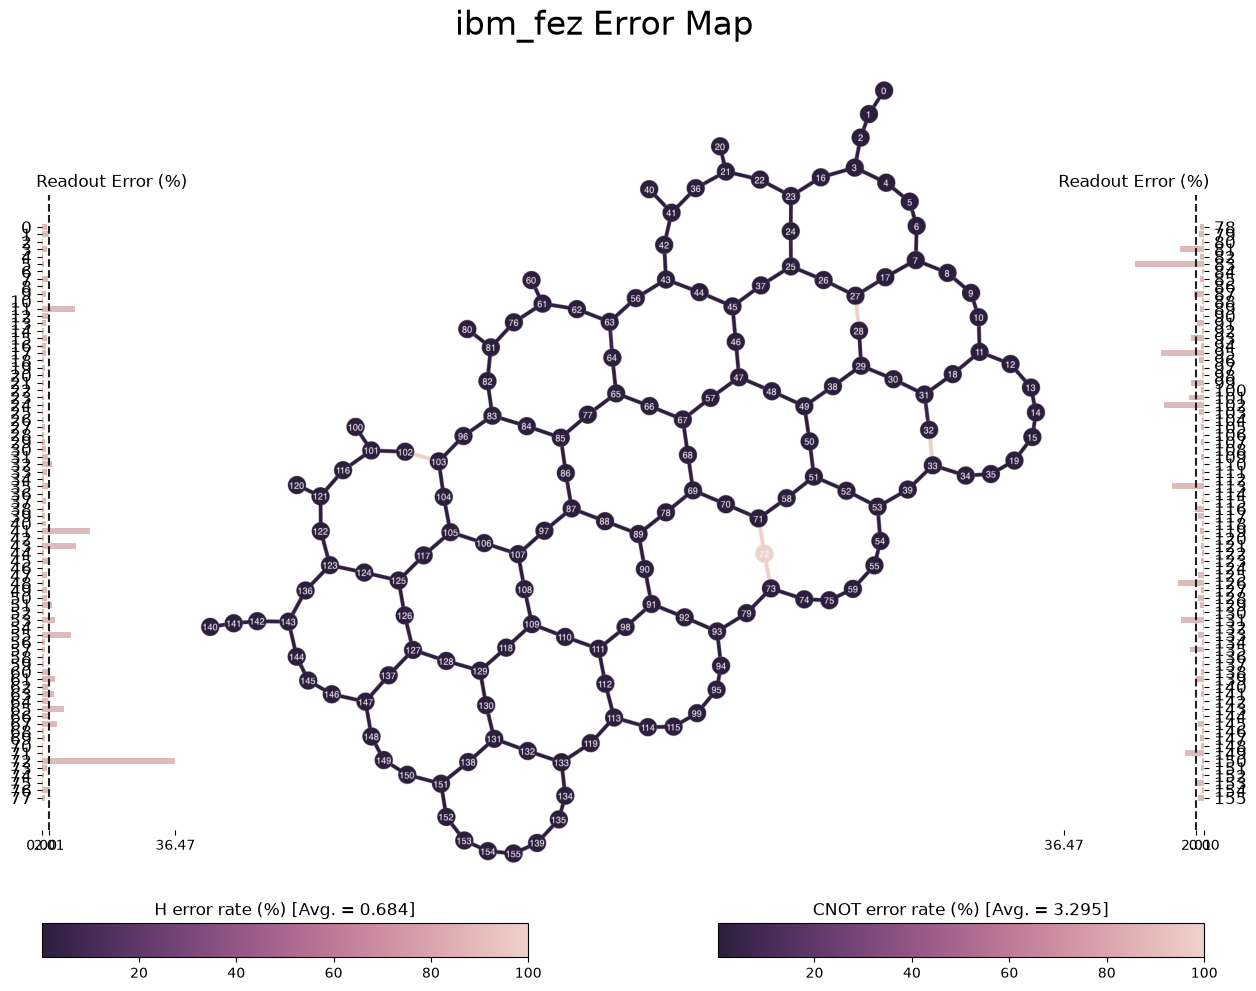

In [35]:
service = QiskitRuntimeService()
backend_hr = service.backend("ibm_fez")
plot_error_map(backend_hr)

### Jordan–Wigner encoding: from orbitals to qubits

The **Jordan–Wigner (JW) transformation** is the dictionary that maps fermionic orbital states onto qubit states:

$$\text{orbital } p \text{ occupied} \;\Longleftrightarrow\; \text{qubit } p = |1\rangle, \qquad
  \text{orbital } p \text{ empty} \;\Longleftrightarrow\; \text{qubit } p = |0\rangle$$

We use $2 \times \texttt{num\_orbitals}$ qubits in total:
- Qubits $0, \ldots, \texttt{num\_orbitals}-1$ → spin-α occupations
- Qubits $\texttt{num\_orbitals}, \ldots, 2\cdot\texttt{num\_orbitals}-1$ → spin-β occupations

This is exactly why, much later in Exercise 2a, a measured bitstring of length `2*num_orbitals` splits cleanly into an α half and a β half.

Two `ffsim` circuit instructions handle the encoding:
- `PrepareHartreeFockJW` — sets the initial qubit state to the Hartree–Fock occupation pattern (the first `num_elec_a` α-qubits and `num_elec_b` β-qubits are $|1\rangle$, the rest $|0\rangle$).
- `UCJOpSpinBalancedJW` — applies the UCJ correlator in the JW qubit basis.

### PRE_INIT passes and gate counts

The `ffsim.qiskit.PRE_INIT` transpiler pass decomposes the high-level `ffsim` gate objects into native hardware gates *before* the main transpilation pass runs.
Running `count_ops()` with and without `PRE_INIT` shows how many native 2-qubit gates the circuit requires — fewer gates means less accumulated noise.

The code below shows the complete setup for the **Heron (`ibm_kingston`)** device as a worked example.
Exercise 1 asks you to redo this mapping for the **Nighthawk (`ibm_miami`)** device.

### The SQD workflow: a brief map

Once the circuit is ready, the rest of this chapter follows a four-step loop:

1. **Sample** — run the LUCJ circuit on hardware and collect bitstrings.
2. **Recover configurations** — fix bitstrings that noise has pushed to the wrong electron count.
3. **Build a subspace** — collect the most frequent (most probable) electron configurations as a basis.
4. **Diagonalize** $\hat{H}$ in that subspace — get an energy estimate; feed the resulting orbital occupancies back to step 2.

Each iteration the subspace gets a little smarter.

In [36]:
# For the Heron device, the alpha-beta interaction happens per every four indicies
alpha_alpha_indices = [(p, p + 1) for p in range(num_orbitals - 1)]
alpha_beta_indices_hr = [(p, p) for p in range(0, num_orbitals, 4)]
alpha_beta_indices_hr = alpha_beta_indices_hr[:5]  # truncate at fifth pair

print(alpha_beta_indices_hr)

[(0, 0), (4, 4), (8, 8), (12, 12), (16, 16)]


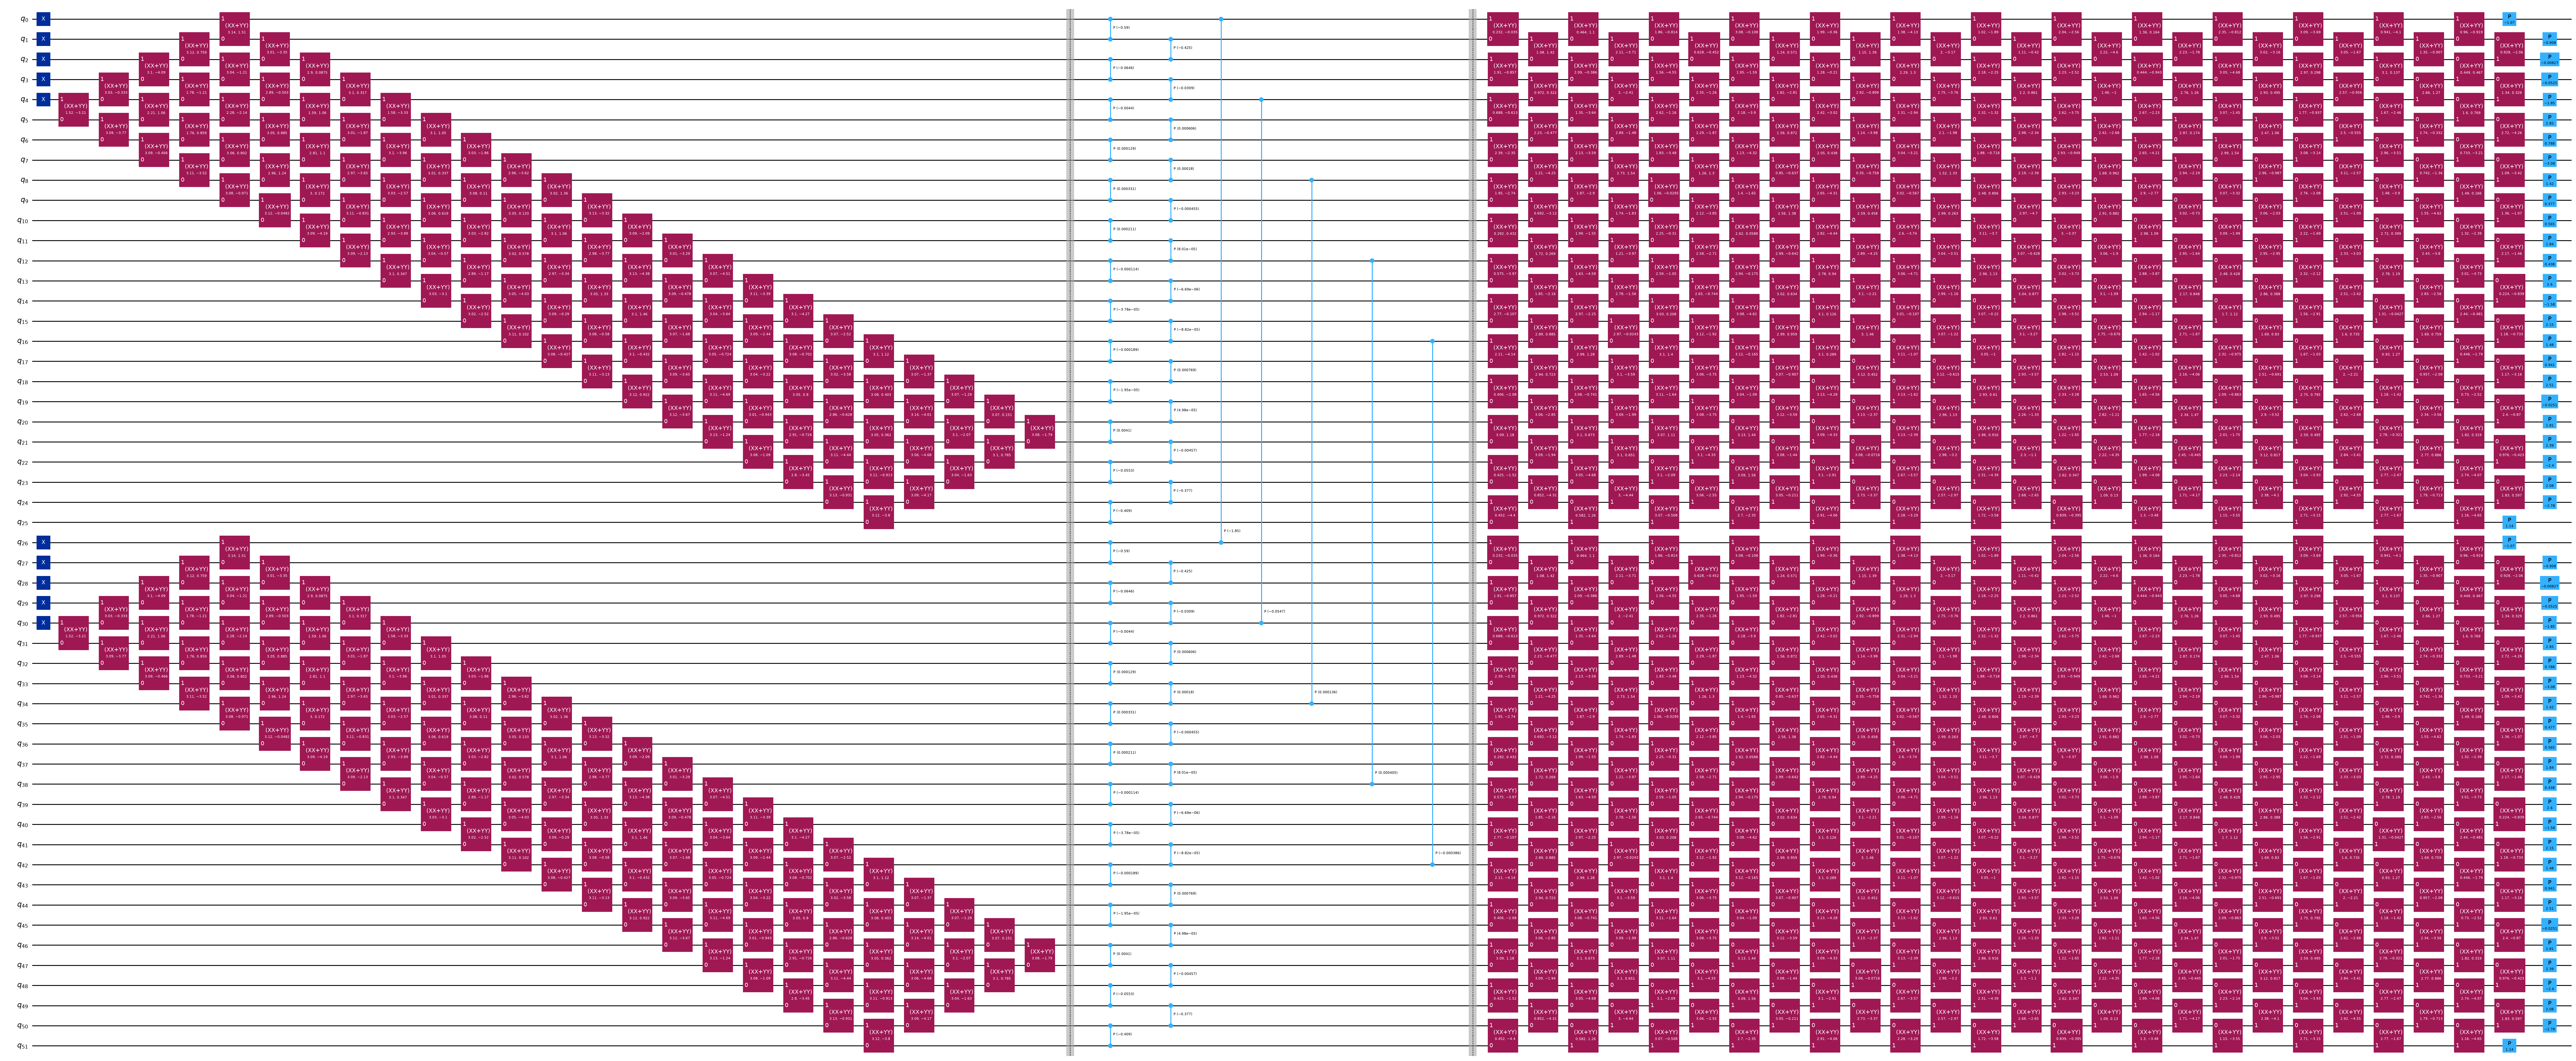

In [38]:
n_reps = 1
ucj_op_hr = ffsim.UCJOpSpinBalanced.from_t_amplitudes(
    t1=t1,
    t2=t2,
    n_reps=n_reps,
    interaction_pairs=(alpha_alpha_indices, alpha_beta_indices_hr),
    optimize=True,
    options=dict(maxiter=20),
)
nelec = (num_elec_a, num_elec_b)

# create an empty quantum circuit
qubits = QuantumRegister(2 * num_orbitals, name="q")
circuit_hr = QuantumCircuit(qubits)

# prepare Hartree-Fock state as the reference state and append it to the quantum circuit
circuit_hr.append(ffsim.qiskit.PrepareHartreeFockJW(num_orbitals, nelec), qubits)

# apply the UCJ operator to the reference state
circuit_hr.append(ffsim.qiskit.UCJOpSpinBalancedJW(ucj_op_hr), qubits)

# investigate into the circuit for execution
inner_circuit_hr = ffsim.qiskit.PRE_INIT.run(circuit_hr)
for i in range(2, 0, -1):
    inner_circuit_hr.data.insert(i, CircuitInstruction(Barrier(num_qubits=2*num_orbitals), qubits))
display(inner_circuit_hr.decompose().draw("mpl", fold=-1))

# insert final measurement
circuit_hr.measure_all()

In [39]:
# select spin a and b layout according to the device topology
spin_a_layout = [
     21,  36,  41,  42,  43,     56,  63,  64,  65,  77,
     85,  86,  87,  97, 107,    108, 109, 118, 129, 128,
    127, 126, 125, 117, 105,    104
]
spin_b_layout = [
     23,  24,  25,  37,  45,     46,  47,  57,  67,  68,
     69,  78,  89,  90,  91,     98, 111, 112, 113, 114,
    115,  99,  95,  94,  93,     79
]

initial_layout = spin_a_layout + spin_b_layout

pass_manager = generate_preset_pass_manager(
    optimization_level=3, backend=backend_hr, initial_layout=initial_layout
)

# without PRE_INIT passes
isa_circuit_hr = pass_manager.run(circuit_hr)
print(f"Gate counts (w/o pre-init passes): {isa_circuit_hr.count_ops()}")

# with PRE_INIT passes
# We will use the circuit generated by this pass manager for hardware execution
pass_manager.pre_init = ffsim.qiskit.PRE_INIT
isa_circuit_hr = pass_manager.run(circuit_hr)
print(f"Gate counts (w/ pre-init passes): {isa_circuit_hr.count_ops()}")

Gate counts (w/o pre-init passes): OrderedDict({'rz': 11710, 'sx': 11700, 'cz': 3524, 'x': 404, 'measure': 52, 'barrier': 1})
Gate counts (w/ pre-init passes): OrderedDict({'sx': 6964, 'rz': 6930, 'cz': 1818, 'measure': 52, 'x': 49, 'barrier': 1})


## Exercise 1: Map LUCJ circuit for the Nighthawk device

Now let's port the same circuit to the **Nighthawk (`ibm_miami`)** device.
Run the error-map cell below and compare the connectivity diagram to Heron's.
Notice how the α and β qubit rails are wired differently — that changes which cross-spin interaction pairs are hardware-native.

> **No access to `ibm_miami`?** Use `FakeMiami` instead — uncomment the second line in the cell below. `FakeMiami` reproduces the Nighthawk device topology (same qubit graph and basis gates) so the circuit mapping and layout exercises work identically; the only difference is that it simulates noise rather than running on real hardware.

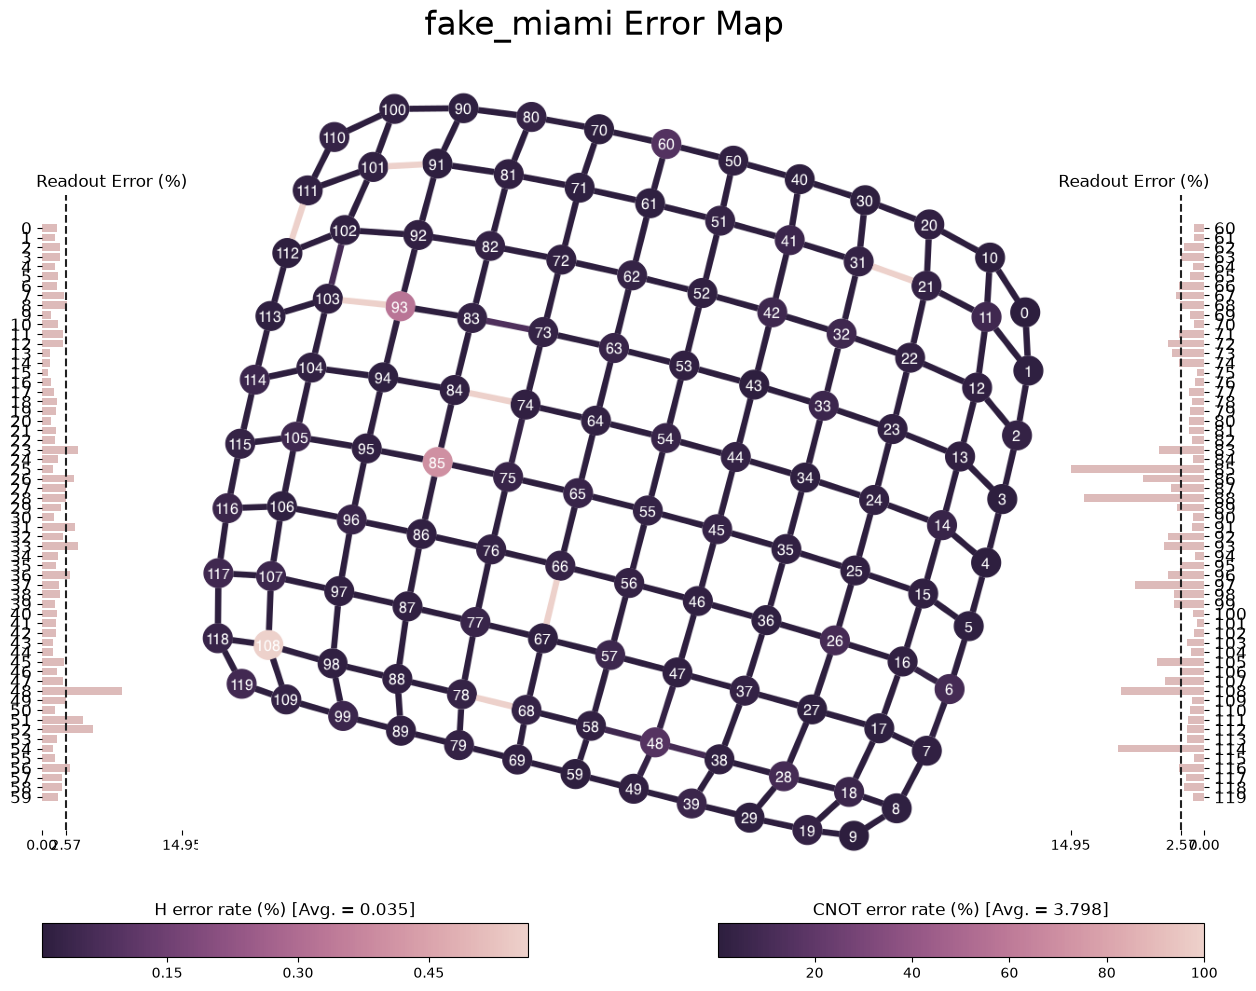

In [40]:
# backend_nh = service.backend("ibm_miami")
# # Use this command to use FakeMiami if you don't have access to ibm_miami
backend_nh = FakeMiami()

plot_error_map(backend_nh)

<a id="exercise_1a"></a>
<div class="alert alert-block alert-success">

<b>Exercise 1a: Select the alpha–beta interaction pairs for the Nighthawk device</b>

**Your Goal:** Fill `alpha_beta_indices_nh` with the cross-spin interaction pairs appropriate for the Nighthawk device topology.

**Background:** Recall from Section 2 that each `(p, q)` tuple in `alpha_beta_indices` means "the Jastrow factor couples α-orbital $p$ to β-orbital $q$, and those two qubits must be physically adjacent on the chip."

- On **Heron (`ibm_kingston`)**, the α and β qubit chains only touch at every 4th site, so we used `[(p, p) for p in range(0, num_orbitals, 4)]` truncated to 5 pairs (there are only 5 hardware-adjacent α–β crossings).
- On **Nighthawk (`ibm_miami`)**, the α and β rails can be laid next to each other so that $p$-th qubit on the α chain can interact with the $p$-th qubit on the β chain for *every* $p$. There is no need to skip indices.

**Hint:**
- **(Recommended)** You can make 24 qubit pairs (truncate at 24) rather than pairing the entire qubits. This is to make it easier to map this to the Nighthawk topology.
- You may notice that you cannot arrange every α and β pair side-by-side, but don't worry about that at this stage.

</div>

In [41]:
# Select alpha-beta interaction pairs according to the Nighthawk device topology
# ---- TODO : Task 1a ----
# Nighthawk can couple α-orbital p to β-orbital p for every p (unlike Heron's every-4th).
# Truncate to 24 pairs for easier hardware mapping.
alpha_beta_indices_nh = [(p, p) for p in range(num_orbitals)][:24]
# ---- End of TODO : Task 1a ----

print(alpha_beta_indices_nh)

[(0, 0), (1, 1), (2, 2), (3, 3), (4, 4), (5, 5), (6, 6), (7, 7), (8, 8), (9, 9), (10, 10), (11, 11), (12, 12), (13, 13), (14, 14), (15, 15), (16, 16), (17, 17), (18, 18), (19, 19), (20, 20), (21, 21), (22, 22), (23, 23)]


In [42]:
grade_lab4c_ex1a(alpha_beta_indices_nh)

Grading your answer. Please wait...

Congratulations! 🎉 Your answer is correct.
You scored 1 on this exercise.




In [43]:
n_reps = 1
ucj_op_nh = ffsim.UCJOpSpinBalanced.from_t_amplitudes(
    t1=t1,
    t2=t2,
    n_reps=n_reps,
    interaction_pairs=(alpha_alpha_indices, alpha_beta_indices_nh),
    optimize=True,
    options=dict(maxiter=20),
)
nelec = (num_elec_a, num_elec_b)

# create an empty quantum circuit
qubits = QuantumRegister(2 * num_orbitals, name="q")
circuit_nh = QuantumCircuit(qubits)

# prepare Hartree-Fock state as the reference state and append it to the quantum circuit
circuit_nh.append(ffsim.qiskit.PrepareHartreeFockJW(num_orbitals, nelec), qubits)

# apply the UCJ operator to the reference state
circuit_nh.append(ffsim.qiskit.UCJOpSpinBalancedJW(ucj_op_nh), qubits)

# investigate the circuit for execution
inner_circuit_nh = ffsim.qiskit.PRE_INIT.run(circuit_nh)
for i in range(2, 0, -1):
    inner_circuit_nh.data.insert(i, CircuitInstruction(Barrier(num_qubits=2*num_orbitals), qubits))
display(inner_circuit_nh.decompose().draw("mpl", fold=-1))

# insert final measurement
circuit_nh.measure_all()

<a id="exercise_1b"></a>
<div class="alert alert-block alert-success">

<b>Exercise 1b: Define the qubit layout for the Nighthawk device</b>

**Your Goal:** Provide `spin_a_layout` and `spin_b_layout` — lists of exactly `num_orbitals` (= 26) physical qubit indices each — that correctly map the α and β spin-orbital chains onto Nighthawk's hardware.

**Background:** `initial_layout` instructs the transpiler to place logical qubit $p$ on physical qubit `initial_layout[p]`. A good layout must satisfy two requirements simultaneously:

1. **Connectivity within each spin sector:** the same-spin nearest-neighbor interactions `alpha_alpha_indices = [(p, p+1) ...]` require physical qubits $p$ and $p+1$ within each list to be hardware-adjacent (connected by a two-qubit gate line on the chip). Each list should therefore trace a *connected path* through the device graph.

2. **α–β adjacency:** according to the pairs provided in exercise 1a, locate the pairs close to each other as much as possible. This time, it is fine to use a few swaps if needed.

**Hint:**
- Every α and β pair may not sit side-by-side. Applying a few swap operations is fine, as long as the swaps can operate in parallel, keeping the circuit depth minimal.
- **(Optional)** If you want to try a more advanced challenge, you can try pairing every 26 qubits in the previous exercise and map them to the Nighthawk. The passing criteria is quite challenging and the grader result may fluctuate according to the transpiler seed. You can make a few trials to get a better transpilation result.
</div>

In [44]:
# select spin a and b layout according to the device topology
# ---- TODO : Task 1b ----
# Constraints:
# 1) Every consecutive α–α / β–β pair must be hardware-adjacent (connected paths).
# 2) As many α–β (p,p) pairs as possible must be adjacent so their CP gates
#    run in parallel (low 2q depth). A perfect 24-rung ladder is impossible on
#    this 12×10 grid with connected rails (max all-cross ladder length = 12),
#    so we maximize native α–β edges under the connectivity constraint.
#
# This layout: ~18/24 native α–β edges, 2q depth ≈ 8 (vs ~30+ for a single dual-rail).
spin_a_layout = [
    117, 107, 108, 98, 88, 78, 68, 58, 48, 38, 28, 18,
     17,  27,  37, 36, 26, 25, 24, 23, 22, 21, 20, 30, 31, 32,
]
spin_b_layout = [
    118, 119, 109, 99, 89, 79, 69, 59, 49, 39, 29, 19,
      9,   8,   7,  6, 16, 15, 14, 13, 12, 11, 10,  0,  1,  2,
]
# ---- End of TODO : Task 1b ----

initial_layout = spin_a_layout + spin_b_layout

pass_manager = generate_preset_pass_manager(
    optimization_level=3, backend=backend_nh, initial_layout=initial_layout
)

# without PRE_INIT passes
isa_circuit_nh = pass_manager.run(circuit_nh)
print(f"Gate counts (w/o pre-init passes): {isa_circuit_nh.count_ops()}")

# with PRE_INIT passes
# We will use the circuit generated by this pass manager for hardware execution
pass_manager.pre_init = ffsim.qiskit.PRE_INIT
isa_circuit_nh = pass_manager.run(circuit_nh)
print(f"Gate counts (w/ pre-init passes): {isa_circuit_nh.count_ops()}")


Gate counts (w/o pre-init passes): OrderedDict({'sx': 11886, 'rz': 11742, 'cz': 3639, 'x': 434, 'measure': 52, 'barrier': 1})
Gate counts (w/ pre-init passes): OrderedDict({'sx': 7080, 'rz': 6933, 'cz': 1901, 'x': 73, 'measure': 52, 'barrier': 1})


In [45]:
grade_lab4c_ex1b(initial_layout, alpha_beta_indices_nh, seed=0)


Grading your answer. Please wait...

Congratulations! 🎉 Your answer is correct.
You scored 1 on this exercise.


## 3. Quantum Sampling

With the circuit mapped to Nighthawk's topology, we submit 2,000 shots to the device.
Each **shot** measures all `2*num_orbitals` qubits and returns one **bitstring** — a binary snapshot of which orbitals are occupied at that moment.
Physically, each bitstring is *one proposed electron configuration*: a candidate for a basis state of the ground state.

The collection of all 2,000 bitstrings, together with how often each distinct configuration appears, is the raw material that SQD will process.

> **Note on runtime:** Running a real hardware job takes 10 seconds on `ibm_miami` or 2 seconds on `ibm_kingston`.
> To keep this notebook self-contained, the cell below submits the job and saves the `job_id`.
> The *following* cell retrieves the pre-computed results from that saved ID — you do not need to resubmit.

In [ ]:
# Option 1: if you have an access to the Nighthawk device, try running the square-lattice circuit.
# sampler = Sampler(mode=backend_nh)
# job = sampler.run([isa_circuit_nh], shots=2_000)
# Option 2: if you don't have an access to the Nighthawk device, you can run Heron fitted circuit.
# sampler = Sampler(mode=backend_hr)
# job = sampler.run([isa_circuit_hr], shots=2_000)
# job_id = job.job_id()
# print(f"Submitted job {job_id}")

The cell below retrieves the completed job and converts the raw measurement outcomes into two arrays:

- `raw_bitstrings` — integer array of shape `(n_unique, 2*num_orbitals)` where each row is a distinct bitstring (each element is 0 or 1).
- `raw_probs` — float array of length `n_unique` giving the empirical probability of each bitstring; `raw_probs[k]` is the fraction of shots that produced `raw_bitstrings[k]`.

In [ ]:
# Retrieve job results
# Use the job_id printed by the submit cell above (your account IDs look like
# "d9k....", not a UUID). A UUID from the lab handout will raise RuntimeJobNotFound.
#
# Option A (recommended): reuse the Job object from the submit cell
# Option B: paste your own job_id string below

job_id = "d9kopfrjf64c739igc00"
job = service.job(job_id)

# If you just ran the submit cell, `job` is already defined:
primitive_result = job.result()
pub_result = primitive_result[0]
bit_array = pub_result.data.meas

# Convert BitArray into bitstring and probability arrays
raw_bitstrings, raw_probs = bit_array_to_arrays(bit_array)
print(f"Loaded {len(raw_bitstrings)} unique bitstrings from job {job.job_id()}")


Loaded 2000 unique bitstrings from job d9kopfrjf64c739igc00


## Exercise 2: Examine the resulting bitstrings

Once the sampling is done, it's time to understand what we have.
The two code cells below let you inspect the shape and contents of `raw_bitstrings` before you begin processing.
Run them first, then complete the two exercises.

In [50]:
print(raw_bitstrings.shape)

(2000, 52)


In [51]:
print(raw_bitstrings[0])

[False False False False False False False False False  True  True  True
  True False  True  True  True  True False False False  True False  True
  True  True False False  True False  True False False  True  True  True
 False  True False  True False False  True False  True  True False  True
  True  True  True  True]


<a id="exercise_2a"></a>
<div class="alert alert-block alert-success">

<b>Exercise 2a: Reshape the raw bitstrings into spin sectors</b>

**Your Goal:** Implement `reshape_bitstring` to divide the **spin-α** and **spin-β** bitstrings from the experiment results.

**Background:** The Jordan–Wigner encoding places the spin-α qubits in the *first* block of each bitstring and the spin-β qubits in the *second* block.
A `1` at position $p$ in the α block means "α-orbital $p$ is occupied"; `0` means empty.  
Separating the two spin sectors lets us:
- Check the electron count per spin independently (Exercise 2b).
- Apply spin-specific corrections during configuration recovery (Exercise 3).

**Hint:**
- The shape of the `raw_bitstrings` is **(2000, 52)**. You should get an array of shape **(2000, 2, 26)**.
- **Bit-ordering caution:** Qiskit returns measurement results in *little-endian* (last qubit measured = first bit in string). After reshaping, verify which block is α by printing `reshaped_bitstrings[0, :]` and checking whether the block matches with the α bitstring. You may need to flip the spin-block ordering so that index 0 is always α.
- Cross-check with the raw `raw_bitstrings[0]` printed above.

</div>

In [52]:
def reshape_bitstring(
    bitstrings: np.ndarray,
    num_orbitals: int
) -> np.ndarray:

    # ---- TODO : Task 2a ----
    # Qiskit bitstrings are little-endian: [β | α] as two halves.
    # Reshape to (n_samples, 2, num_orbitals), then flip so index 0 is α.
    reshaped_bitstrings = bitstrings.reshape(-1, 2, num_orbitals)[:, ::-1, :]
    # ---- End of TODO : Task 2a ----

    return reshaped_bitstrings

reshaped_bitstrings = reshape_bitstring(raw_bitstrings, num_orbitals)
print(reshaped_bitstrings[0, :])


[[False False  True False  True False False  True  True  True False  True
  False  True False False  True False  True  True False  True  True  True
   True  True]
 [False False False False False False False False False  True  True  True
   True False  True  True  True  True False False False  True False  True
   True  True]]


In [53]:
grade_lab4c_ex2a(reshape_bitstring, raw_bitstrings)

Grading your answer. Please wait...

Congratulations! 🎉 Your answer is correct.
You scored 1 on this exercise.


<a id="exercise_2b"></a>
<div class="alert alert-block alert-success">

<b>Exercise 2b: Count electrons per sample (Hamming weight)</b>

**Your Goal:** Implement `hamming_weight` that takes the reshaped bitstring array and returns an integer array giving the number of occupied orbitals for each spin sector in each sample.

**Background:** The **Hamming weight** of a binary string is simply its number of 1s.
In our context, Hamming weight = number of electrons of that spin in that sample.

A *valid* sample must have exactly 5 spin-α electrons **and** 5 spin-β electrons (particle number conservation).
In a noiseless world, every shot would be valid. On real hardware, bit-flip errors and other noise mechanisms push some bitstrings outside the correct particle-number sector — those samples are physically meaningless and would corrupt the diagonalization if used directly.

Counting the Hamming weight is the first step to detecting these bad samples.

**Hint:** Sum over the last axis (the orbital axis).

</div>

In [54]:
def hamming_weight(bitstrings: np.ndarray) -> np.ndarray:

    # ---- TODO : Task 2b ----
    # Count occupied orbitals (1s) per spin sector → shape (n_samples, 2)
    weight = bitstrings.sum(axis=-1)
    # ---- End of TODO : Task 2b ----

    return weight

print(hamming_weight(reshaped_bitstrings)[0])


[15 12]


In [55]:
grade_lab4c_ex2b(hamming_weight)

Grading your answer. Please wait...

Congratulations! 🎉 Your answer is correct.
You scored 1 on this exercise.


The cell below checks how many samples already have the correct electron counts — i.e., how many shots are "valid" before any repair. Never be surprised by finding an outcome `0` :)

In [56]:
print(int(2e3*np.sum(raw_probs[np.all(hamming_weight(reshaped_bitstrings) == nelec)])))

0


## Exercise 3: Recover the bitstring

### Why configuration recovery is necessary

The true molecular ground state lives entirely within the **fixed-particle-number sector**: configurations with exactly `(num_elec_a, num_elec_b)` electrons.
Quantum mechanics conserves particle number — the physical molecule cannot spontaneously gain or lose electrons.

However, a real quantum device introduces **bit-flip errors** (and other noise) that change some `0`s to `1`s and vice versa.
A single bit-flip moves a bitstring *out* of the physical sector; suddenly, the sample reports the wrong number of electrons.
That sample is physically meaningless and, if fed directly to the diagonalizer, would contaminate the subspace with non-physical configurations.

**Configuration recovery** repairs each broken sample by flipping the minimum number of bits needed to restore the correct electron count, choosing *which* bits to flip based on our current best estimate of each orbital's average occupancy.

### Initializing occupancy from Hartree–Fock

The recovery algorithm needs a prior estimate of "how occupied is each orbital, on average?"
We bootstrap this with the **Hartree–Fock occupancy**: the `num_elec_a` highest-index orbitals are fully occupied (occupancy = 1), the rest are empty (occupancy = 0).
As the SQD loop progresses, this is replaced by the actual orbital occupancies measured from the diagonalized quantum state — so the recovery improves with each iteration.

In [57]:
initial_occupancy = np.zeros((2, num_orbitals), dtype=float)
initial_occupancy[:, -num_elec_a:] = 1.
print(initial_occupancy)

[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1.
  1. 1.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1.
  1. 1.]]


<a id="exercise_3a"></a>
<div class="alert alert-block alert-success">

<b>Exercise 3a: Define the bit-flip probability function</b>

**Your Goal:** Implement `weight_flip_0_to_1(occupancy)` which, given an array of orbital occupancies in $[0, 1]$, returns the probability weight for flipping each orbital from empty (0) to occupied (1).

**Background:** When a sample is *missing* an electron (too few 1s), we must flip some empty orbital to occupied.
We want to preferentially fill orbitals that are *usually* occupied — because the true ground state probably has those orbitals filled.
Conversely, we should almost never fill an orbital that is usually empty.

The function:

$$W_{0\to1}(\text{occ}) = e^{\text{occ}} - 1, \qquad 0 \le \text{occ} \le 1$$

has a kind of that behavior:
- $W_{0\to1}(0) = 0$ — never fill a never-occupied orbital.
- $W_{0\to1}(1) = e - 1 \approx 1.718$ — strongly prefer filling an always-occupied orbital.
- Monotonically increasing in between.

The companion function `weight_flip_1_to_0(occ) = weight_flip_0_to_1(1 - occ)` is already provided; removing an electron favors orbitals that are usually empty (high probability of being 0).

</div>

In [58]:
def weight_flip_0_to_1(occupancy: np.ndarray) -> np.ndarray:

    # ---- TODO : Task 3a ----
    # Prefer flipping empty→occupied on orbitals that are usually occupied
    prob = np.exp(occupancy) - 1
    # ---- End of TODO : Task 3a ----

    return prob

def weight_flip_1_to_0(occupancy):
    return weight_flip_0_to_1(1-occupancy)


In [59]:
grade_lab4c_ex3a(weight_flip_0_to_1)

Grading your answer. Please wait...

Congratulations! 🎉 Your answer is correct.
You scored 1 on this exercise.


<a id="exercise_3b"></a>
<div class="alert alert-block alert-success">

<b>Exercise 3b: Recover bitstring configurations to the correct electron count</b>

**Your Goal:** Complete the `recover_configurations` function by filling in the three-branch correction logic inside the per-spin loop.

**Background — the algorithm, step by step:**

The outer loop iterates over every bitstring sample. For each sample and each spin sector `i` (0 = α, 1 = β):

1. Compute `weight[i]` = Hamming weight = number of electrons in sector `i` (you wrote this in Exercise 2b).
2. Compare `weight[i]` to `num_elec[i]`:

   - **Too few electrons** (`weight[i] < num_elec[i]`): we must flip `num_elec[i] - weight[i]` empty bits to 1.
     - Find empty orbitals
     - Get flip weights for those candidates
     - Normalize the weights to make a probability distribution
     - Randomly select which to flip
     - Set the chosen bits to `True`

   - **Too many electrons** (`weight[i] > num_elec[i]`): we must flip `weight[i] - num_elec[i]` occupied bits to 0.
     - Mirror the procedure above, but make sure that you are choosing occupied bits to flip.

   - **Exactly right** (`weight[i] == num_elec[i]`): leave the spin sector unchanged.

**Hint:** Each branch needs four lines: find candidates with `np.where`, compute and normalize probabilities, call `rand_seed.choice` to choose which bit to flip, and flip the bits.

**Note:** The output format: each corrected bitstring is converted to a string and accumulated into `corrected_dict` (a `defaultdict` that merges any bitstrings that end up identical after correction).

</div>

In [60]:
def recover_configurations(
    bitstrings: np.ndarray,
    probs: np.ndarray,
    occupancy: np.ndarray,
    num_orbitals: int,
    num_elec: tuple[int, int],
    rand_seed: np.random.Generator,
) -> tuple[np.ndarray, np.ndarray]:
    # SCIResult.orbital_occupancies is a (α, β) tuple; initial_occupancy is (2, norb).
    # Normalize so occupancy[i, candidates] always works.
    occupancy = np.asarray(occupancy, dtype=float)

    corrected_dict: defaultdict[str, float] = defaultdict(float)
    for bitstring, freq, weight in zip(bitstrings, probs, hamming_weight(bitstrings)):
        bs_corrected = bitstring.copy()
        for i in range(2):
            # ---- TODO : Task 3b ----
            if weight[i] < num_elec[i]:
                # Too few electrons: flip empty (0) → occupied (1)
                candidates = np.where(~bs_corrected[i].astype(bool))[0]
                flip_probs = weight_flip_0_to_1(occupancy[i, candidates])
                flip_probs = flip_probs / np.sum(flip_probs)
                chosen = rand_seed.choice(
                    candidates, size=int(num_elec[i] - weight[i]), replace=False, p=flip_probs
                )
                bs_corrected[i, chosen] = True
            elif weight[i] > num_elec[i]:
                # Too many electrons: flip occupied (1) → empty (0)
                candidates = np.where(bs_corrected[i].astype(bool))[0]
                flip_probs = weight_flip_1_to_0(occupancy[i, candidates])
                flip_probs = flip_probs / np.sum(flip_probs)
                chosen = rand_seed.choice(
                    candidates, size=int(weight[i] - num_elec[i]), replace=False, p=flip_probs
                )
                bs_corrected[i, chosen] = False
            # else: already correct electron count — leave unchanged
            # ---- End of TODO : Task 3b ----
        bs_str = "".join("1" if bit else "0" for bit in bs_corrected.flatten())
        corrected_dict[bs_str] += freq

    bs_mat_out = np.array([[bit == "1" for bit in bs] for bs in corrected_dict]).reshape(-1, 2, num_orbitals)
    freqs_out = np.array([f for f in corrected_dict.values()])
    freqs_out = np.abs(freqs_out) / np.sum(np.abs(freqs_out))

    return bs_mat_out, freqs_out

recovered_bitstrings, recovered_probs = recover_configurations(
    reshaped_bitstrings, raw_probs, initial_occupancy, num_orbitals, nelec, np.random.default_rng())


The cell below shows how many samples are valid (correct electron count) **after** configuration recovery — compare to the pre-recovery number from Exercise 2b.

In [61]:
print(np.rint(2e3*np.sum(recovered_probs[np.all(hamming_weight(recovered_bitstrings) == nelec, axis=1)])).astype(int))

2000


In [62]:
grade_lab4c_ex3b(recover_configurations)

Grading your answer. Please wait...

Congratulations! 🎉 Your answer is correct.
You scored 1 on this exercise.


### From recovered bitstrings to the diagonalization subspace

With all samples now in the correct particle-number sector, we prepare them for diagonalization:

1. **`subsample`** splits the recovered configurations into `num_batches` independent batches of `samples_per_batch` samples each. Running the eigensolver on multiple independent batches gives us variance estimates (the box plot later shows the spread) and reduces the chance of getting stuck in an unlucky set of configurations.

2. **`bitstring_matrix_to_integers`** packs each binary bitstring into a single Python integer — the standard "determinant label" format that the selected-CI eigensolver `solve_sci_batch` expects. These integer labels, called **CI strings**, identify each electron configuration (Slater determinant) uniquely.

3. **`build_subspace`** takes the CI strings, deduplicates within each batch, sorts by marginal probability (most-sampled first), optionally prepends a user-specified `include` set, and truncates to `max_dim` configurations per spin. The result is the **subspace basis**: the set of Slater determinants the Hamiltonian will be projected onto.

In [63]:
subsamples = np.array(subsample(recovered_bitstrings.reshape(-1, 2*num_orbitals), recovered_probs, samples_per_batch=20, num_batches=5))
subsamples = subsamples.reshape(*subsamples.shape[:-1], 2, -1)
print(subsamples.shape)
print(subsamples[4, 19])

(5, 20, 2, 26)
[[False False False False False False False False False False False False
   True False False False False False  True  True False False  True False
  False  True]
 [False False False False False False False  True False False False False
  False False False False False False False  True False False False  True
   True  True]]


In [64]:
ci_strs = np.array([bitstring_matrix_to_integers(samples[:, i]) for samples in subsamples for i in range(2)])
ci_strs = ci_strs.reshape(-1, 2, ci_strs.shape[-1])
print(ci_strs.shape)
print(ci_strs[0])

(5, 2, 20)
[[25165976    16594  4210737 21233984       47   339969       79  1049746
   4212746    33814     8207    18458    65690  2097810     4167      167
    262171 41945154    16661    67595]
 [  532556 33554462 25169926 20971548 19398736  2097179  4325649  1048605
  18972676       31      158 33587213  9699337  7340044    16399  8391692
   4325432  4259907  4228101   344070]]


In [65]:
def build_subspace(subsamples, include=np.empty((2, 0), dtype=int), max_dim=(None, None)):

    subspaces = []
    for samples in subsamples:
        subspace_list = []
        for i in range(2):

            # Get the single-spin bitstrings and counts.
            bitstrings, counts = np.unique(samples[i], return_counts=True)

            # Sort the single-spin bitstrings in descending order by marginal probability.
            bitstrings = bitstrings[np.argsort(counts)[::-1]]
            
            # Prioritize explicitly requested bitstrings, then sampled bitstrings
            subspace = np.concatenate((include[i], bitstrings))

            # Get unique values while preserving the original order
            _, indices = np.unique(subspace, return_index=True)
            indices.sort()
            subspace = subspace[indices]

            # Truncate bitstrings to the maximum dimension.
            subspace = subspace[:max_dim[i]]
            subspace.sort()

            subspace_list.append(subspace)
        subspaces.append(subspace_list)

    return subspaces

subspace = build_subspace(ci_strs, max_dim=(15, 15))
print(np.array(subspace).shape)

(5, 2, 15)


### SQD loop parameters

Before running the self-consistent loop, here is what each parameter controls:

| Parameter | Meaning |
|---|---|
| `max_iterations` | How many recover → subsample → diagonalize cycles to run. More iterations let the occupancy estimate converge. |
| `num_batches` | Number of independent subspace batches per iteration. More batches → better statistics (wider box plot range). |
| `samples_per_batch` | Configurations per batch. Larger → richer subspace but more classical eigensolver work. |
| `max_dim` | Maximum number of Slater determinants per spin sector in the subspace. Controls the dimension of the Hamiltonian matrix. |
| `spin_sq=0.0` | Enforce total spin $S^2 = 0$ (singlet) — correct for ground-state N₂ and prevents the solver from finding excited spin states. |
| `solve_sci_batch` | The **selected-CI (SCI) eigensolver**: given the subspace basis CI strings and the Hamiltonian integrals `hcore`/`eri`, it builds and diagonalizes the projected Hamiltonian matrix and returns the lowest eigenvalue + eigenvector. |

In [69]:
# SQD options
energy_tol = 1e-3
occupancies_tol = 1e-3
max_iterations = 5
seed=142

# Eigenstate solver options
num_batches = 5
samples_per_batch = 500
max_dim = (300, 300)
max_cycle = 200

# Pass options to the built-in eigensolver. If you just want to use the defaults,
# you can omit this step, in which case you would not specify the sci_solver argument
# in the call to diagonalize_fermionic_hamiltonian below.
sci_solver = partial(solve_sci_batch, spin_sq=0.0, max_cycle=max_cycle)

# List to capture intermediate results
result_history = []

def callback(results: list[SCIResult]):
    result_history.append(results)
    iteration = len(result_history)
    print(f"Iteration {iteration}")
    for i, result in enumerate(results):
        print(f"\tSubsample {i}")
        print(f"\t\tEnergy: {result.energy + nuclear_repulsion_energy}")
        print(f"\t\tSubspace dimension: {np.prod(result.sci_state.amplitudes.shape)}")

### The self-consistent SQD loop

The loop below implements the four-step SQD cycle end-to-end:

1. **Recover** — call `recover_configurations` using the *current* `current_occupancies` as the flip-probability prior.
2. **Subsample** — draw `num_batches` independent batches of `samples_per_batch` configurations.
3. **Build subspace** — convert to CI strings and call `build_subspace` to get the Slater determinant basis.
4. **Diagonalize** — call `sci_solver` to project and diagonalize $\hat{H}$ in that subspace.

After diagonalization, the key feedback step is:
```python
current_occupancies = current_result.orbital_occupancies
```
The eigenvector produced by the solver tells us how occupied each orbital is on average in the approximate ground state.
This updated occupancy prior feeds back into step 1 in the *next* iteration, making the configuration recovery progressively more accurate.
The loop runs for `max_iterations` cycles and tracks the best (lowest-energy) result seen across all batches and iterations.

In [71]:
result_history = []

rng = np.random.default_rng(seed)
current_occupancies = initial_occupancy
best_result = None
sci_solver = solve_sci_batch

# Convert BitArray into bitstring and probability arrays
raw_bitstrings, raw_probs = bit_array_to_arrays(bit_array)

# Run configuration recovery loop
for _ in range(max_iterations):
    reshaped_bitstrings = reshape_bitstring(raw_bitstrings, num_orbitals)

    # If we do have average orbital occupancy information, use it to refine the
    # full set of noisy configurations
    bitstrings, probs = recover_configurations(
        reshaped_bitstrings, raw_probs, current_occupancies, num_orbitals, nelec, rand_seed=rng
    )

    # Subsample batches of bitstrings
    subsamples = np.array(subsample(
        bitstrings.reshape(-1, 2*num_orbitals),
        probs,
        samples_per_batch=samples_per_batch,
        num_batches=num_batches,
        rand_seed=rng,
    ))
    subsamples = subsamples.reshape(*subsamples.shape[:-1], 2, -1)

    ci_strs = np.array([bitstring_matrix_to_integers(samples[:, i]) for samples in subsamples for i in range(2)])
    ci_strs = ci_strs.reshape(-1, 2, ci_strs.shape[-1])

    # Convert bitstrings to CI strings and include requested and carryover strings
    subspace = build_subspace(ci_strs, max_dim=max_dim)

    # Run diagonalization
    results = sci_solver(subspace, hcore, eri, num_orbitals, nelec)

    # Call callback function
    callback(results)

    # Get best result from batch
    best_result_in_batch = min(results, key=lambda result: result.energy)

    # Check if the energy is the lowest seen so far
    if best_result is None or best_result_in_batch.energy < best_result.energy:
        best_result = copy.deepcopy(best_result_in_batch)

    # Save the current result and occupancies
    current_result = copy.deepcopy(best_result_in_batch)
    # SCIResult.orbital_occupancies is a (α, β) tuple; recover_configurations
    # indexes it as occupancy[i, candidates], so stack into a (2, norb) array.
    current_occupancies = np.asarray(current_result.orbital_occupancies)

# best_result is not None because there must have been at least one iteration
best_result = cast(SCIResult, best_result)

Iteration 1
	Subsample 0
		Energy: -108.5663422972222
		Subspace dimension: 90000
	Subsample 1
		Energy: -108.57380163340379
		Subspace dimension: 90000
	Subsample 2
		Energy: -108.5452455203808
		Subspace dimension: 90000
	Subsample 3
		Energy: -108.53076379764822
		Subspace dimension: 90000
	Subsample 4
		Energy: -108.53625123831591
		Subspace dimension: 90000
Iteration 2
	Subsample 0
		Energy: -103.34234968744444
		Subspace dimension: 90000
	Subsample 1
		Energy: -103.5419539621775
		Subspace dimension: 90000
	Subsample 2
		Energy: -103.2742710896196
		Subspace dimension: 90000
	Subsample 3
		Energy: -105.35099792118346
		Subspace dimension: 90000
	Subsample 4
		Energy: -104.26618615486319
		Subspace dimension: 90000
Iteration 3
	Subsample 0
		Energy: -105.41265939433862
		Subspace dimension: 90000
	Subsample 1
		Energy: -104.28450356337811
		Subspace dimension: 90000
	Subsample 2
		Energy: -105.30265345661783
		Subspace dimension: 90000
	Subsample 3
		Energy: -105.91351005855122
		

Best energy = -108.57380163340379


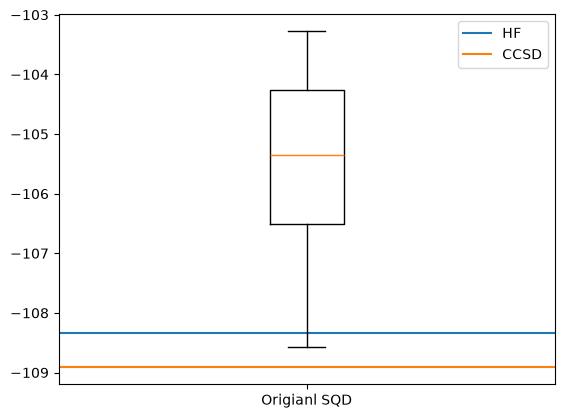

In [72]:
print(f"Best energy = {best_result.energy + nuclear_repulsion_energy}")

plt.axhline(scf.e_tot, color="C0", label="HF")
plt.axhline(ccsd.e_tot, color="C1", label="CCSD")
plt.boxplot(
    [x.energy + nuclear_repulsion_energy for results in result_history for x in results],
    tick_labels=['Origianl SQD'],
)
plt.legend(loc='upper right')
plt.show()

# Will submit the best subspace basis
best_subspace = (best_result.sci_state.ci_strs_a, best_result.sci_state.ci_strs_b)

You may see that the original SQD method finds a better energy estimate than the HF state — this is already a non-trivial result, as it shows the quantum samples are steering the diagonalization into a physically meaningful region of Hilbert space.
However, the result is not yet as good as the classical CCSD benchmark.

The gap between SQD and CCSD reveals a limitation of pure sampling: hardware noise and finite shot counts mean the sampler misses some chemically important electron configurations — particularly the *low-energy*, *near-HF* configurations that contribute strongly to the ground state but may not be the *most frequently measured* bitstrings.

**Exercise 4 directly addresses this gap** by augmenting the sampled subspace with a hand-picked set of chemically motivated configurations.

## Exercise 4: Freeze subspace configurations

### Classical subspace diagonalization

Before combining classical and quantum subspaces, let's see what happens if we diagonalize in a *purely classical, physically motivated* subspace — no quantum samples at all.

The key insight is that the **lowest-energy electron configurations** are those closest to Hartree–Fock: the `num_elec` electrons sit in the lowest-energy orbitals, with only small rearrangements ("excitations") away from the HF reference.
We can enumerate these systematically using `itertools.combinations`:

In [73]:
from itertools import combinations

print(list(combinations(range(5), 3)))

[(0, 1, 2), (0, 1, 3), (0, 1, 4), (0, 2, 3), (0, 2, 4), (0, 3, 4), (1, 2, 3), (1, 2, 4), (1, 3, 4), (2, 3, 4)]


<a id="exercise_4"></a>
<div class="alert alert-block alert-success">

<b>Exercise 4: Build an HF-like frozen subspace</b>

**Your Goal:** Construct `hf_like_bitstrings` — up to 300 Slater determinants built from the *lowest-orbital* electron configurations — and convert them to `hf_like_ci_strings` suitable for the eigensolver.

**Background:** Returning to our concert-hall analogy: instead of hoping the quantum sampler stumbles upon the most important seating arrangements, we manually enumerate the front-row configurations and hand them directly to the eigensolver.
The "front rows" here are the orbital combinations where electrons prefer to sit — the lowest-energy orbitals first, then progressively more excited arrangements.

**Hint:**
- Consider starting from a fully occupied bitstring.
- Apply `bitstring_matrix_to_integers` to convert to CI string format.
- Don't forget that you should provide both of α and β strings to run diagonalization!

</div>

In [80]:
# ---- TODO : Task 4 ----
# Lab HF convention (same as initial_occupancy): the num_elec_a *highest-index*
# orbitals are occupied. Hint: start from a fully occupied bitstring, then choose
# which orbitals to empty via combinations — so the first config is the HF reference.
n_configs = 300
n_empty = num_orbitals - num_elec_a

hf_like_bitstrings = np.ones((n_configs, num_orbitals), dtype=bool)
for i, empty in enumerate(combinations(range(num_orbitals), n_empty)):
    if i >= n_configs:
        break
    hf_like_bitstrings[i, list(empty)] = False

# Closed-shell: same determinants for α and β → CI strings shape (2, n_configs)
hf_ci = bitstring_matrix_to_integers(hf_like_bitstrings)
hf_like_ci_strings = np.array([hf_ci, hf_ci])
print(hf_like_bitstrings.shape, hf_like_ci_strings.shape)
print("HF reference bitstring:", hf_like_bitstrings[0].astype(int))
print("First few CI ints:", hf_ci[:5])
# ---- End of TODO : Task 4 ----


(300, 26) (2, 300)
HF reference bitstring: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1]
First few CI ints: [31 47 55 59 61]


In [81]:
grade_lab4c_ex4(hf_like_ci_strings)

Grading your answer. Please wait...

Congratulations! 🎉 Your answer is correct.
You scored 1 on this exercise.


Now try diagonalizing the Hamiltonian in this purely classical, HF-like subspace:

In [82]:
hf_result = sci_solver([hf_like_ci_strings], hcore, eri, num_orbitals, nelec)[0]
print(f"HF-like Subspace Diagonalized Energy: {hf_result.energy + nuclear_repulsion_energy}")
print(f"Subspace dimension: {np.prod(hf_result.sci_state.amplitudes.shape)}")

HF-like Subspace Diagonalized Energy: -108.7888209567441
Subspace dimension: 90000


You may find that the HF-like subspace energy is **lower** than the original (pure quantum sampling) SQD result.
This confirms that the hand-picked low-energy configurations are genuinely important for the ground state, and that the quantum sampler alone might drop some important configurations due to the instable noisy environment.

### Combining quantum samples with a frozen classical subspace

The most powerful approach combines the two:
- Fix a small number of the HF-like configurations as a **guaranteed anchor** (`include = hf_like_ci_strings[:, :100]` — first 100 configurations).
- Let the quantum sampler supply the remaining `max_dim - 100` configurations per batch as usual.

This way, every diagonalization starts from a solid classical foundation and the quantum device explores the rest of the space.
How do you expect the result to compare to the pure-sampling and pure-HF cases?

In [83]:
# List to capture intermediate results
pm_result_history = []

def callback(results: list[SCIResult]):
    pm_result_history.append(results)
    iteration = len(pm_result_history)
    print(f"Iteration {iteration}")
    for i, result in enumerate(results):
        print(f"\tSubsample {i}")
        print(f"\t\tEnergy: {result.energy + nuclear_repulsion_energy}")
        print(f"\t\tSubspace dimension: {np.prod(result.sci_state.amplitudes.shape)}")

# We are fixing 100 lowest orbital subspaces during the SQD loop.
# The remaining 200 samples are obtained from quantum samples as usual.
include = hf_like_ci_strings[:, :100]  # Fix 100 lowest orbital subspace

rng = np.random.default_rng(seed)
current_occupancies = initial_occupancy
best_result = None
sci_solver = solve_sci_batch

# Convert BitArray into bitstring and probability arrays
raw_bitstrings, raw_probs = bit_array_to_arrays(bit_array)

# Run configuration recovery loop
for _ in range(max_iterations):
    reshaped_bitstrings = reshape_bitstring(raw_bitstrings, num_orbitals)

    # If we do have average orbital occupancy information, use it to refine the
    # full set of noisy configurations
    bitstrings, probs = recover_configurations(
        reshaped_bitstrings, raw_probs, current_occupancies, num_orbitals, nelec, rand_seed=rng
    )

    # Subsample batches of bitstrings
    subsamples = np.array(subsample(
        bitstrings.reshape(-1, 2*num_orbitals),
        probs,
        samples_per_batch=samples_per_batch,
        num_batches=num_batches,
        rand_seed=rng,
    ))
    subsamples = subsamples.reshape(*subsamples.shape[:-1], 2, -1)

    ci_strs = np.array([bitstring_matrix_to_integers(samples[:, i]) for samples in subsamples for i in range(2)])
    ci_strs = ci_strs.reshape(-1, 2, ci_strs.shape[-1])

    # Convert bitstrings to CI strings and include requested and carryover strings
    subspace = build_subspace(ci_strs, include, max_dim=max_dim)

    # Run diagonalization
    results = sci_solver(subspace, hcore, eri, num_orbitals, nelec)

    # Call callback function
    callback(results)

    # Get best result from batch
    best_result_in_batch = min(results, key=lambda result: result.energy)

    # Check if the energy is the lowest seen so far
    if best_result is None or best_result_in_batch.energy < best_result.energy:
        best_result = copy.deepcopy(best_result_in_batch)

    # Save the current result and occupancies
    current_result = copy.deepcopy(best_result_in_batch)
    # SCIResult.orbital_occupancies is a (α, β) tuple; recover_configurations
    # indexes it as occupancy[i, candidates], so stack into a (2, norb) array.
    current_occupancies = np.asarray(current_result.orbital_occupancies)

# best_result is not None because there must have been at least one iteration
best_result = cast(SCIResult, best_result)

Iteration 1
	Subsample 0
		Energy: -108.80346658098719
		Subspace dimension: 90000
	Subsample 1
		Energy: -108.79557295137454
		Subspace dimension: 90000
	Subsample 2
		Energy: -108.79123711639429
		Subspace dimension: 90000
	Subsample 3
		Energy: -108.79849084426905
		Subspace dimension: 90000
	Subsample 4
		Energy: -108.79428392898501
		Subspace dimension: 90000
Iteration 2
	Subsample 0
		Energy: -108.76627547237865
		Subspace dimension: 90000
	Subsample 1
		Energy: -108.76573607458722
		Subspace dimension: 90000
	Subsample 2
		Energy: -108.76569279298774
		Subspace dimension: 90000
	Subsample 3
		Energy: -108.76713772464026
		Subspace dimension: 90000
	Subsample 4
		Energy: -108.76631105028918
		Subspace dimension: 90000
Iteration 3
	Subsample 0
		Energy: -108.76729347698844
		Subspace dimension: 90000
	Subsample 1
		Energy: -108.76673894785594
		Subspace dimension: 90000
	Subsample 2
		Energy: -108.76768250057174
		Subspace dimension: 90000
	Subsample 3
		Energy: -108.766023525033


Best energy (frozen subspace) = -108.80346658098719


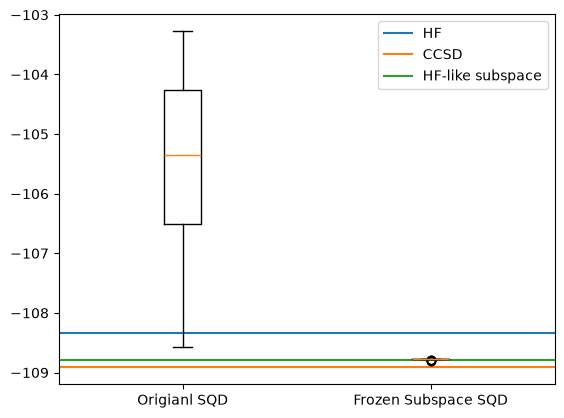

In [84]:
print(f"Best energy (frozen subspace) = {best_result.energy + nuclear_repulsion_energy}")

plt.axhline(scf.e_tot, color="C0", label="HF")
plt.axhline(ccsd.e_tot, color="C1", label="CCSD")
plt.axhline(hf_result.energy + nuclear_repulsion_energy, color="C2", label="HF-like subspace")
plt.boxplot(
    [[x.energy + nuclear_repulsion_energy for results in result_history for x in results],
     [x.energy + nuclear_repulsion_energy for results in pm_result_history for x in results]],
    tick_labels=["Origianl SQD", "Frozen Subspace SQD"],
)
plt.legend(loc='upper right')
plt.show()

Observe two improvements in the **Frozen Subspace SQD** box plot:

1. **Lower energy** — the best estimate is closer to the CCSD reference, because the 100 frozen HF-like configurations guarantee that the most important near-HF determinants are always in the subspace.
2. **Tighter spread** — the box plot is narrower, meaning the result is more *stable* across different batches. Anchoring the subspace reduces variance from unlucky sampling.

Note also: the HF-like subspace is *not* the best possible subspace — it is just a systematic and physically motivated choice. The quantum sampler can, in principle, discover configurations with even lower energy that no classical heuristic would have enumerated.
This is the promise of the scored exercise below.

### Scored Exercise: Find your best subspace!

<a id="exercise_bonus"></a>
<div class="alert alert-block alert-success">

**Your Goal:** Minimize `best_energy` — the ground-state energy estimate for N₂ — as far below the CCSD benchmark as you can push it.
The lower your energy, the higher your score.

**Metric:** `best_energy = best_result.energy + nuclear_repulsion_energy`. Lower is better.

**What you can change:** Anything! Some ideas:

- **Better ansatz:** add more LUCJ layers or further optimize the parameters to get better samples.
- **Better flip probability:** experiment with different functional forms for `prob_flip_0_to_1` (e.g. a steeper exponential, or a threshold function).
- **More iterations:** increase `max_iterations` or `num_batches` and let the occupancy prior converge further.
- **Classical post-processing:** try some classical algorithms to keep and carryover good bitstrings.

Submit your best result with the cell below.

</div>

In [85]:
best_energy = best_result.energy + nuclear_repulsion_energy
best_subspace = (best_result.sci_state.ci_strs_a, best_result.sci_state.ci_strs_b)
grade_lab4c_exbonus(best_energy, best_subspace)  # Submit the best energy and subspace

Grading your answer. Please wait...

Congratulations! 🎉 Your answer is submitted.
You scored 61 on this exercise.


# Additional information

**Created by:** Boseong Kim

**Version:** 1.0.0